In [2]:
import json
import numpy as np
from pathlib import Path

DATA_DIR = Path("../data/raw/tokyo")

print("Data directory:", DATA_DIR.resolve())

Data directory: C:\Users\temka\OneDrive\Desktop\MyProjects\TokyoFlowAI\data\raw\tokyo


In [3]:
with open(DATA_DIR / "vis_traj" / "394_JP_Tokyo.json", "r", encoding="utf-8") as f:
    vis_traj = json.load(f)

print(type(vis_traj))
print("Length:", len(vis_traj))
print("First item:")
print(vis_traj[0])

<class 'list'>
Length: 1000
First item:
{'path': [[139.86626302851175, 35.6866566572019], [139.8675735968295, 35.68500964844465], [139.86852457951335, 35.68561950773998], [139.86799474903927, 35.6877123192166], [139.86915230250582, 35.68643995767666], [139.86645687951426, 35.687193233199274], [139.8680174779183, 35.68643605764275], [139.8676636418256, 35.687671886054545], [139.86806559560617, 35.687402054493774], [139.8672791633087, 35.686006287646556], [139.86633898559535, 35.684854447600046], [139.86760053690915, 35.686931488925644], [139.86737973185814, 35.68654798949776], [139.86843189764392, 35.68808843685309], [139.86772825960225, 35.68796235305905], [139.86714387642706, 35.68617368691515], [139.86574605579392, 35.68596879925884], [139.86630262999392, 35.6877158434742], [139.8696274174786, 35.68628571163867], [139.86783391002652, 35.68830948246341], [139.86966841862255, 35.686015411967915], [139.86842934366197, 35.6861382032974], [139.86844547439532, 35.68618749158336], [139.8689

In [4]:
traj = np.load(
    DATA_DIR / "traj" / "394_JP_Tokyo.npy",
    allow_pickle=True
)

print("Shape:", traj.shape)
print("Dtype:", traj.dtype)
print("First item:")
print(traj[0])

Shape: (32, 77)
Dtype: float64
First item:
[10814.3359375  12575.45996094 15841.3359375   6193.6796875
  5208.18603516  6327.63037109  6596.26367188 12478.55664062
 18995.18554688  6438.67236328  7465.07324219 17462.91015625
 11340.62011719 17052.56054688 41116.92578125 29755.02734375
 22242.65234375 24469.5234375  15799.0078125  16244.0234375
 29021.38476562 15361.13769531 15336.68847656 40665.3359375
 30798.31640625 36168.52734375 61518.140625   36519.1328125
 37730.80078125 25496.45898438  9275.33984375  5886.95605469
 19000.40234375 17407.5625     17245.61523438 34444.85546875
 25526.890625   31009.91210938 61047.9609375  38012.796875
 32831.015625   51315.3359375  41398.578125   34909.1875
 43643.578125   34755.25390625 37212.7890625  48674.6875
 22534.31640625 20145.67578125 25715.70117188 11085.05273438
 12334.1484375  19318.5703125  10613.07226562 17915.53710938
 31167.72265625 28245.13671875 18892.32226562 18085.73046875
 29134.17773438 16582.86132812 15227.82617188 22329.5937

In [5]:
city_data = np.load(
    DATA_DIR / "city_data" / "394_JP_Tokyo.npz",
    allow_pickle=True
)

print("Keys:", city_data.files)

for key in city_data.files:
    arr = city_data[key]
    print(
        key,
        "shape =", getattr(arr, "shape", None),
        "dtype =", getattr(arr, "dtype", None)
    )

Keys: ['grid', 'poi', 'pop', 'traj']
grid shape = () dtype = object
poi shape = (32, 77, 34) dtype = float32
pop shape = (32, 77) dtype = float64
traj shape = (165328, 48) dtype = int64


In [6]:
with open(DATA_DIR / "grid" / "394_JP_Tokyo.json", "r", encoding="utf-8") as f:
    grid = json.load(f)

print(type(grid))
print("Length:", len(grid))

if isinstance(grid, list):
    print(grid[0])
elif isinstance(grid, dict):
    print(list(grid.items())[:3])

<class 'list'>
Length: 1000
{'path': [[139.86626302851175, 35.6866566572019], [139.8675735968295, 35.68500964844465], [139.86852457951335, 35.68561950773998], [139.86799474903927, 35.6877123192166], [139.86915230250582, 35.68643995767666], [139.86645687951426, 35.687193233199274], [139.8680174779183, 35.68643605764275], [139.8676636418256, 35.687671886054545], [139.86806559560617, 35.687402054493774], [139.8672791633087, 35.686006287646556], [139.86633898559535, 35.684854447600046], [139.86760053690915, 35.686931488925644], [139.86737973185814, 35.68654798949776], [139.86843189764392, 35.68808843685309], [139.86772825960225, 35.68796235305905], [139.86714387642706, 35.68617368691515], [139.86574605579392, 35.68596879925884], [139.86630262999392, 35.6877158434742], [139.8696274174786, 35.68628571163867], [139.86783391002652, 35.68830948246341], [139.86966841862255, 35.686015411967915], [139.86842934366197, 35.6861382032974], [139.86844547439532, 35.68618749158336], [139.8689138131772, 3

In [8]:
from pathlib import Path
import geopandas as gpd

boundary_dir = DATA_DIR / "shp_file" / "394_JP_Tokyo"

shp_files = list(boundary_dir.rglob("*.shp"))
print(shp_files)

[WindowsPath('../data/raw/tokyo/shp_file/394_JP_Tokyo/data1/zhangyuheng/world-traj/scripts/cities_global_1625_shp/394_JP_Tokyo/regions.shp')]


In [9]:
tokyo_boundary = gpd.read_file(shp_files[0])

print(tokyo_boundary.crs)
print(tokyo_boundary.head())

EPSG:32654
  locations                                           geometry
0      0-10  POLYGON ((347295.101 3963134.835, 347295.101 3...
1      1-10  POLYGON ((347295.101 3963134.835, 347328.881 3...
2       3-6  POLYGON ((355552.892 3952124.448, 355552.892 3...
3       3-7  POLYGON ((355552.892 3952124.448, 354364.697 3...
4       4-4  POLYGON ((358305.489 3946619.255, 358305.489 3...


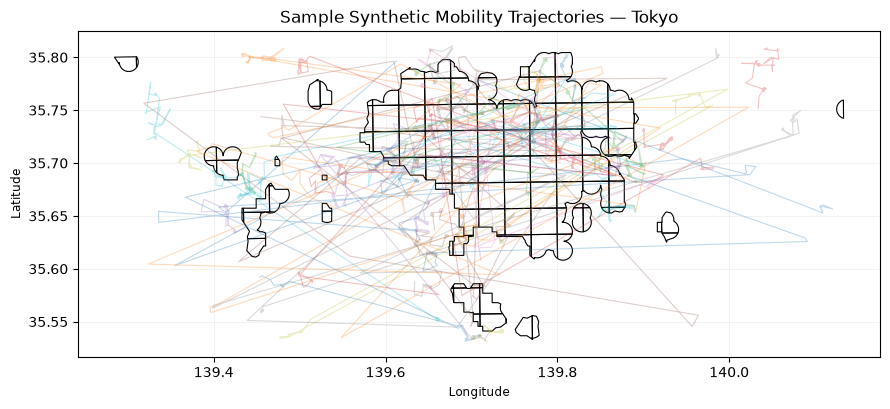

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure boundary is in latitude/longitude
if tokyo_boundary.crs is None:
    tokyo_boundary = tokyo_boundary.set_crs("EPSG:4326")
else:
    tokyo_boundary = tokyo_boundary.to_crs("EPSG:4326")

# Reproducible random sample
rng = np.random.default_rng(42)
sample_ids = rng.choice(len(vis_traj), size=60, replace=False)

fig, ax = plt.subplots(figsize=(9, 9))

# Plot Tokyo boundary
tokyo_boundary.plot(
    ax=ax,
    facecolor="none",
    edgecolor="black",
    linewidth=0.8
)

# Plot sample trajectories
for idx in sample_ids:
    path = vis_traj[idx]["path"]

    lon = [p[0] for p in path]
    lat = [p[1] for p in path]

    ax.plot(
        lon,
        lat,
        linewidth=0.8,
        alpha=0.28
    )

ax.set_title("Sample Synthetic Mobility Trajectories — Tokyo")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=0.15)

plt.tight_layout()

plt.savefig(
    "../figures/tokyo_trajectories_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

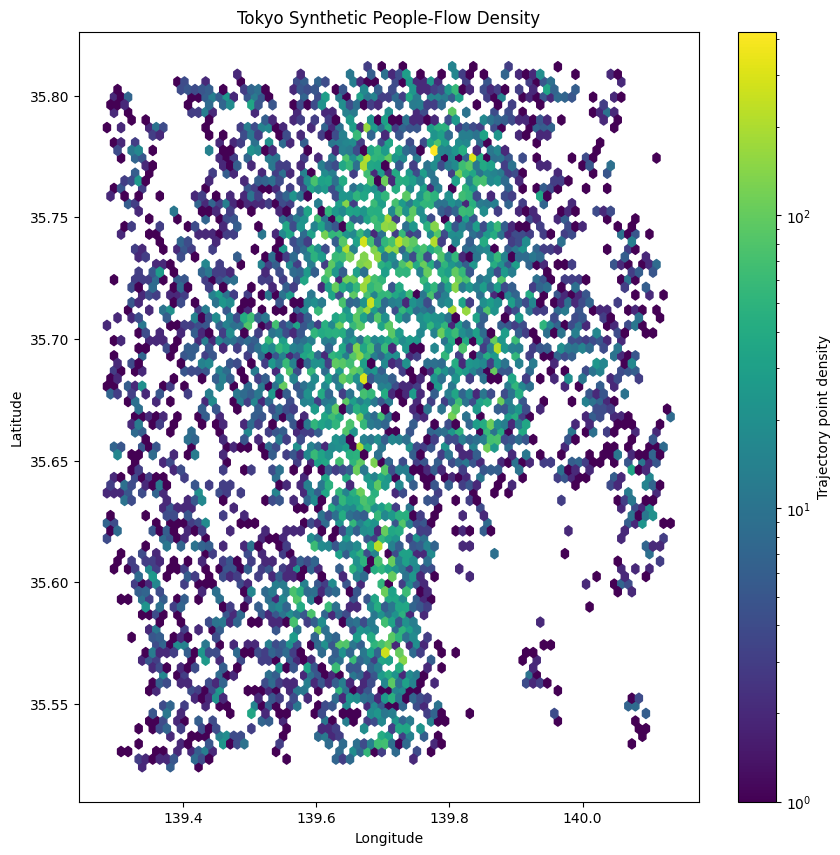

In [ ]:
all_lon = []
all_lat = []

for item in vis_traj:
    for lon, lat in item["path"]:
        all_lon.append(lon)
        all_lat.append(lat)

plt.figure(figsize=(10, 10))

plt.hexbin(
    all_lon,
    all_lat,
    gridsize=80,
    mincnt=1,
    bins="log"
)

plt.colorbar(label="Trajectory point density")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Tokyo Synthetic People-Flow Density")

plt.show()

from pathlib import Path

FIGURE_DIR = Path("../figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURE_DIR / "tokyo_people_flow_density.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()